# Customer Segmentation with RFM and Clustering

CSC 3730, Fall 2026, Group 6: Hammaad Alam, Nick Jaramillo, Fahd Khattak, Damien Nguyen, Madison Nguyen, Taylor Wall, Demetri Williams

The goal of this project is to group the customers of an online retailer by how they buy, so that marketing can treat different kinds of customers differently. There are no labels in the data, so this is an unsupervised learning problem. We build Recency, Frequency, and Monetary (RFM) features for each customer, cluster them with K-means, and compare the result with agglomerative clustering to see if a second method finds the same groups.

The data is the Online Retail dataset from the UCI Machine Learning Repository (Chen, 2015). It has 541,909 invoice lines from a UK online gift shop between December 2010 and December 2011. The dataset page says many of the customers are wholesalers.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Every figure is also saved to figures/ so it can be reused in the report and slides
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Preprocessing

RFM needs purchases that belong to a known customer, so we remove rows with no CustomerID, cancellations, and rows with a zero or negative quantity or price. `original_df` is kept unchanged so we can compare against the raw data.

In [2]:
# Load the dataset and preserve original_df
original_df = pd.read_excel("Online Retail.xlsx")
print("Shape:", original_df.shape)

Shape: (541909, 8)


In [3]:
# Display the first few rows of the dataset
original_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# Summarize numeric columns and transaction dates
original_df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
# Inspect column types and non-null counts
original_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
# Count missing values and exact duplicates, duplicates are assessed after cleaning
display(original_df.isna().sum())
print("Number of duplicate rows:", original_df.duplicated().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Number of duplicate rows: 5268


About a quarter of the rows have no CustomerID. We can't tell who made those purchases, so they can't be used for customer-level features and we drop them.

In [7]:
# Keep transactions with a known CustomerID for customer-level analysis
customer_df = original_df.dropna(subset=['CustomerID'])
print("New Shape:", customer_df.shape)

New Shape: (406829, 8)


Invoices that start with C are cancellations. We drop those rows but keep the original purchase rows, so Monetary is what the customer ordered, not what they kept after returns.

In [8]:
# Identify cancellation rows among transactions with a known CustomerID
canceled_transactions = customer_df[customer_df["InvoiceNo"].astype(str).str.startswith("C")]

print("Canceled rows:", len(canceled_transactions))
print("Unique canceled invoices:", canceled_transactions["InvoiceNo"].nunique())
print("Customers with cancellations:", canceled_transactions["CustomerID"].nunique())

Canceled rows: 8905
Unique canceled invoices: 3654
Customers with cancellations: 1589


In [9]:
# Exclude cancellation rows, original purchases remain in the data
non_canceled_df = customer_df[~customer_df["InvoiceNo"].astype(str).str.startswith("C")]
non_canceled_df.shape

(397924, 8)

In [10]:
# Select rows with zero or negative quantities or prices for analysis
non_positive_rows = non_canceled_df[(non_canceled_df["Quantity"] <= 0) | (non_canceled_df["UnitPrice"] <= 0)]
print("Rows with zero or negative quantity or price:", len(non_positive_rows))

Rows with zero or negative quantity or price: 40


In [11]:
# Keep positive quantities and prices, then copy for further preprocessing
positive_sales_df = non_canceled_df[(non_canceled_df["Quantity"] > 0) & (non_canceled_df["UnitPrice"] > 0)]
cleaned_df = positive_sales_df.copy()

In [12]:
# Calculate spending per line item before refunds and cancellations
cleaned_df["TotalPrice"] = cleaned_df["Quantity"] * cleaned_df["UnitPrice"]

In [13]:
# Report cleaned purchase rows, total rows removed, and unique customers
print("\nCleaned rows:", len(cleaned_df))
print("Rows removed:", len(original_df) - len(cleaned_df))
print("Unique customers:", cleaned_df["CustomerID"].nunique())


Cleaned rows: 397884
Rows removed: 144025
Unique customers: 4338


In [14]:
# Rows remaining after each cleaning step
cleaning_steps = pd.DataFrame(
    {"Rows": [len(original_df), len(customer_df), len(non_canceled_df), len(cleaned_df)]},
    index=["Raw data", "Known CustomerID", "Cancellations removed", "Positive quantity and price"],
)
cleaning_steps["PctOfRaw"] = cleaning_steps["Rows"] / len(original_df) * 100
display(cleaning_steps.round(1))

# Exact duplicate rows still in the cleaned data and how much spending they account for
duplicate_rows = cleaned_df[cleaned_df.duplicated()]
print("Exact duplicate rows in cleaned data:", len(duplicate_rows))
print(f"Share of cleaned rows: {len(duplicate_rows) / len(cleaned_df):.2%}")
print(f"Share of total spending: {duplicate_rows['TotalPrice'].sum() / cleaned_df['TotalPrice'].sum():.2%}")

,Rows,PctOfRaw
Raw data,541909,100.0
Known CustomerID,406829,75.1
Cancellations removed,397924,73.4
Positive quantity and price,397884,73.4


Exact duplicate rows in cleaned data: 5192
Share of cleaned rows: 1.30%
Share of total spending: 0.27%


There are still about 5,200 exact duplicate rows (1.3% of rows, 0.27% of spending). We can't tell if these are data errors or the same item entered twice on an order, so we keep them. They don't affect Recency or Frequency, and the effect on Monetary is tiny.

In [15]:
display(cleaned_df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## Basic exploratory data analysis

,Sales,Orders
InvoiceDate,,
2010-12,572713.890,1400
2011-01,569445.040,987
2011-02,447137.350,997
2011-03,595500.760,1321
2011-04,469200.361,1149
2011-05,678594.560,1555
2011-06,661213.690,1393
2011-07,600091.011,1331
2011-08,645343.900,1280


Observed date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


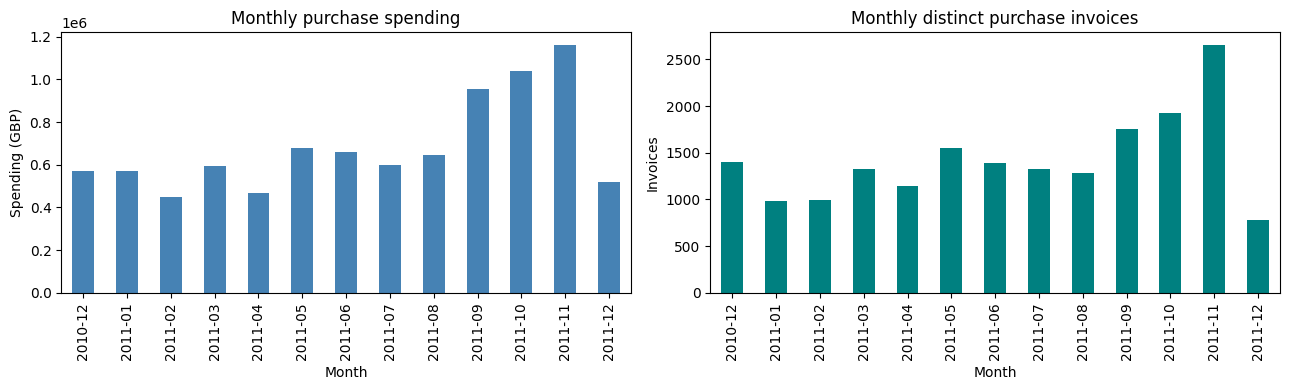

In [16]:
# Summarize monthly purchase spending and distinct orders
monthly_sales = cleaned_df.groupby(
    cleaned_df["InvoiceDate"].dt.to_period("M")
).agg(
    Sales=("TotalPrice", "sum"),
    Orders=("InvoiceNo", "nunique"),
)

display(monthly_sales)

print(
    "Observed date range:",
    cleaned_df["InvoiceDate"].min(),
    "to",
    cleaned_df["InvoiceDate"].max(),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

monthly_sales["Sales"].plot.bar(
    ax=axes[0], color="steelblue",
    title="Monthly purchase spending",
)

monthly_sales["Orders"].plot.bar(
    ax=axes[1], color="teal",
    title="Monthly distinct purchase invoices",
)

axes[0].set_ylabel("Spending (GBP)")
axes[1].set_ylabel("Invoices")

for ax in axes:
    ax.set_xlabel("Month")

plt.tight_layout()
save_fig("monthly_sales")
plt.show()

,Sales,Customers,SalesSharePct
Country,,,
United Kingdom,7308391.554,3920,82.011638
Netherlands,285446.340,9,3.203156
EIRE,265545.900,3,2.979842
Germany,228867.140,94,2.568249
France,209024.050,87,2.345578
Australia,138521.310,9,1.554427
Spain,61577.110,30,0.690992
Switzerland,56443.950,21,0.633390
Belgium,41196.340,25,0.462288


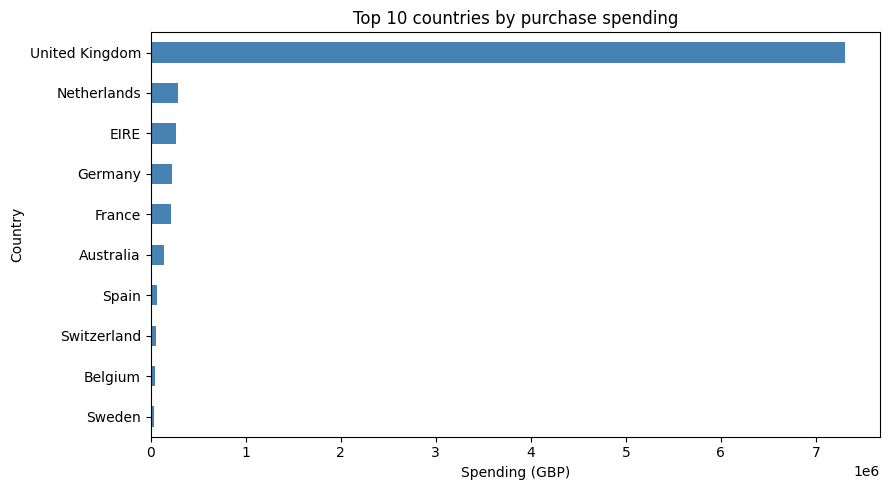

In [17]:
# Spending and share by country
country_sales = (
    cleaned_df.groupby("Country")
    .agg(Sales=("TotalPrice", "sum"), Customers=("CustomerID", "nunique"))
    .sort_values("Sales", ascending=False)
)
country_sales["SalesSharePct"] = country_sales["Sales"] / country_sales["Sales"].sum() * 100

display(country_sales)

top10 = country_sales.head(10).sort_values("Sales")
top10["Sales"].plot.barh(figsize=(9, 5), color="steelblue")

plt.title("Top 10 countries by purchase spending")
plt.xlabel("Spending (GBP)")
plt.ylabel("Country")
plt.tight_layout()
save_fig("top_countries")
plt.show()

,Orders,Spending,AverageOrderValue
count,4338.000000,4338.000000,4338.000000
mean,4.272015,2054.266460,419.166289
std,7.697998,8989.230441,1796.537944
min,1.000000,3.750000,3.450000
50%,2.000000,674.485000,293.900000
90%,9.000000,3646.531000,667.243070
99%,30.000000,19880.995700,2031.161200
max,209.000000,280206.020000,84236.250000


Customers with one purchase invoice: 34.4%


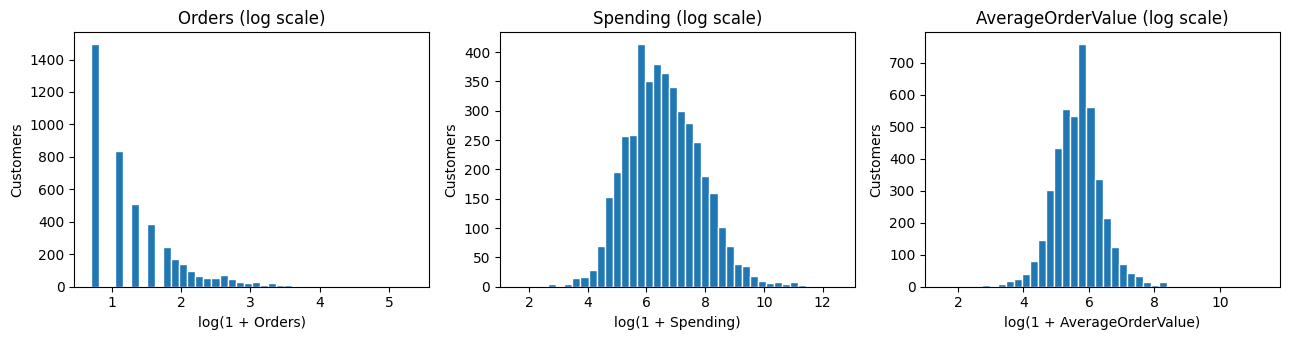

,InvoiceNo,CustomerID,InvoiceDate,Quantity,UnitPrice,TotalPrice
540421,581483,16446.0,2011-12-09 09:15:00,80995,2.08,168469.60
61619,541431,12346.0,2011-01-18 10:01:00,74215,1.04,77183.60
222680,556444,15098.0,2011-06-10 15:28:00,60,649.50,38970.00
173382,551697,16029.0,2011-05-03 13:46:00,1,8142.75,8142.75
348325,567423,17450.0,2011-09-20 11:05:00,1412,5.06,7144.72
52711,540815,15749.0,2011-01-11 12:55:00,3114,2.10,6539.40
160546,550461,15749.0,2011-04-18 13:20:00,3114,2.10,6539.40
421601,573003,14646.0,2011-10-27 12:11:00,2400,2.08,4992.00
52709,540815,15749.0,2011-01-11 12:55:00,1930,2.55,4921.50
160542,550461,15749.0,2011-04-18 13:20:00,1930,2.40,4632.00


In [18]:
# Summarize purchasing behavior by customer
customer_patterns = cleaned_df.groupby("CustomerID").agg(
    Orders=("InvoiceNo", "nunique"),
    Spending=("TotalPrice", "sum"),
)
customer_patterns["AverageOrderValue"] = (
    customer_patterns["Spending"] / customer_patterns["Orders"]
)

display(customer_patterns.describe(percentiles=[0.5, 0.9, 0.99]))
print(f"Customers with one purchase invoice: {(customer_patterns['Orders'] == 1).mean():.1%}")

# View the distributions on log scales
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes, ["Orders", "Spending", "AverageOrderValue"]):
    ax.hist(np.log1p(customer_patterns[column]), bins=40, edgecolor="white")
    ax.set(title=f"{column} (log scale)", xlabel=f"log(1 + {column})", ylabel="Customers")

plt.tight_layout()
save_fig("customer_distributions")
plt.show()

# Inspect the largest individual purchases
display(
    cleaned_df.nlargest(
        10, "TotalPrice"
    )[["InvoiceNo", "CustomerID", "InvoiceDate", "Quantity", "UnitPrice", "TotalPrice"]]
)

Things we noticed:

- Sales are fairly flat until August, then rise from September to a peak in November. December 2011 is low because the data stops on December 9.
- The UK makes up 82% of spending and about 90% of customers.
- Most customers are small (median 2 orders and about 675 GBP, and 34% ordered only once), but a few spend far more. Since orders and spending are so skewed, we log-transform before clustering.

In [19]:
# Save the cleaned purchases for the next notebook (02_rfm_kmeans.ipynb)
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
cleaned_df.to_pickle(DATA_DIR / "cleaned_df.pkl")